In [8]:
drive.flush_and_unmount()
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [6]:
from google.colab import drive
drive.mount('/content/drive')

import os
import shutil

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
drive_runs = "/content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/xView/runs/xview_yolov8s_merged_v3"
local_runs = "/content/xView_local/runs/xview_yolov8s_merged_v3"

os.makedirs(os.path.dirname(local_runs), exist_ok=True)
if not os.path.exists(local_runs):
    shutil.copytree(drive_runs, local_runs)
    print("Modèle copié en local.")
else:
    print("Déjà présent en local.")

model_path = os.path.join(local_runs, "weights", "best.pt")
print(f"Modèle présent : {os.path.exists(model_path)}")

Modèle copié en local.
Modèle présent : True


In [9]:
drive_val_images = "/content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/xView/val_images"
local_val_images = "/content/xView_local/val_images"

if not os.path.exists(local_val_images):
    print("Copie des images de validation...")
    shutil.copytree(drive_val_images, local_val_images)
    print("Terminé.")
else:
    print("Déjà présent en local.")

n_val = len([f for f in os.listdir(local_val_images) if f.endswith('.tif') and not f.startswith('._')])
print(f"Images de validation disponibles : {n_val}")

Copie des images de validation...
Terminé.
Images de validation disponibles : 281


In [10]:
n_val = len([f for f in os.listdir(local_val_images) if f.endswith('.tif')])
print(f"Images de validation en local : {n_val}")

Images de validation en local : 281


In [11]:
!pip install ultralytics -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 35.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.0/90.0 kB 6.7 MB/s eta 0:00:00


In [12]:
from ultralytics import YOLO
model = YOLO(model_path)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [13]:
sample_images = [f for f in os.listdir(local_val_images) if f.endswith('.tif') and not f.startswith('._')][:10]

for img_name in sample_images:
    img_path = os.path.join(local_val_images, img_name)
    results = model.predict(img_path, save=True, conf=0.20, project="/content/xView_local/runs", name="inference_demo2")
    print(f"{img_name} : {len(results[0].boxes)} objets détectés")


image 1/1 /content/xView_local/val_images/2428.tif: 544x640 41 Buildings, 2 Rail Vehicles, 32 Small Cars, 1 Vehicle Lot, 983.4ms
Speed: 35.5ms preprocess, 983.4ms inference, 50.0ms postprocess per image at shape (1, 3, 544, 640)
Results saved to /content/xView_local/runs/inference_demo2
2428.tif : 76 objets détectés

image 1/1 /content/xView_local/val_images/963.tif: 608x640 129 Buildings, 610.7ms
Speed: 6.4ms preprocess, 610.7ms inference, 1.6ms postprocess per image at shape (1, 3, 608, 640)
Results saved to /content/xView_local/runs/inference_demo2
963.tif : 129 objets détectés

image 1/1 /content/xView_local/val_images/690.tif: 608x640 1 Building, 1 Small Car, 958.7ms
Speed: 12.0ms preprocess, 958.7ms inference, 1.4ms postprocess per image at shape (1, 3, 608, 640)
Results saved to /content/xView_local/runs/inference_demo2
690.tif : 2 objets détectés

image 1/1 /content/xView_local/val_images/2570.tif: 448x640 17 Boats, 271 Buildings, 1 Rail Vehicle, 11 Small Cars, 703.3ms
Speed: 

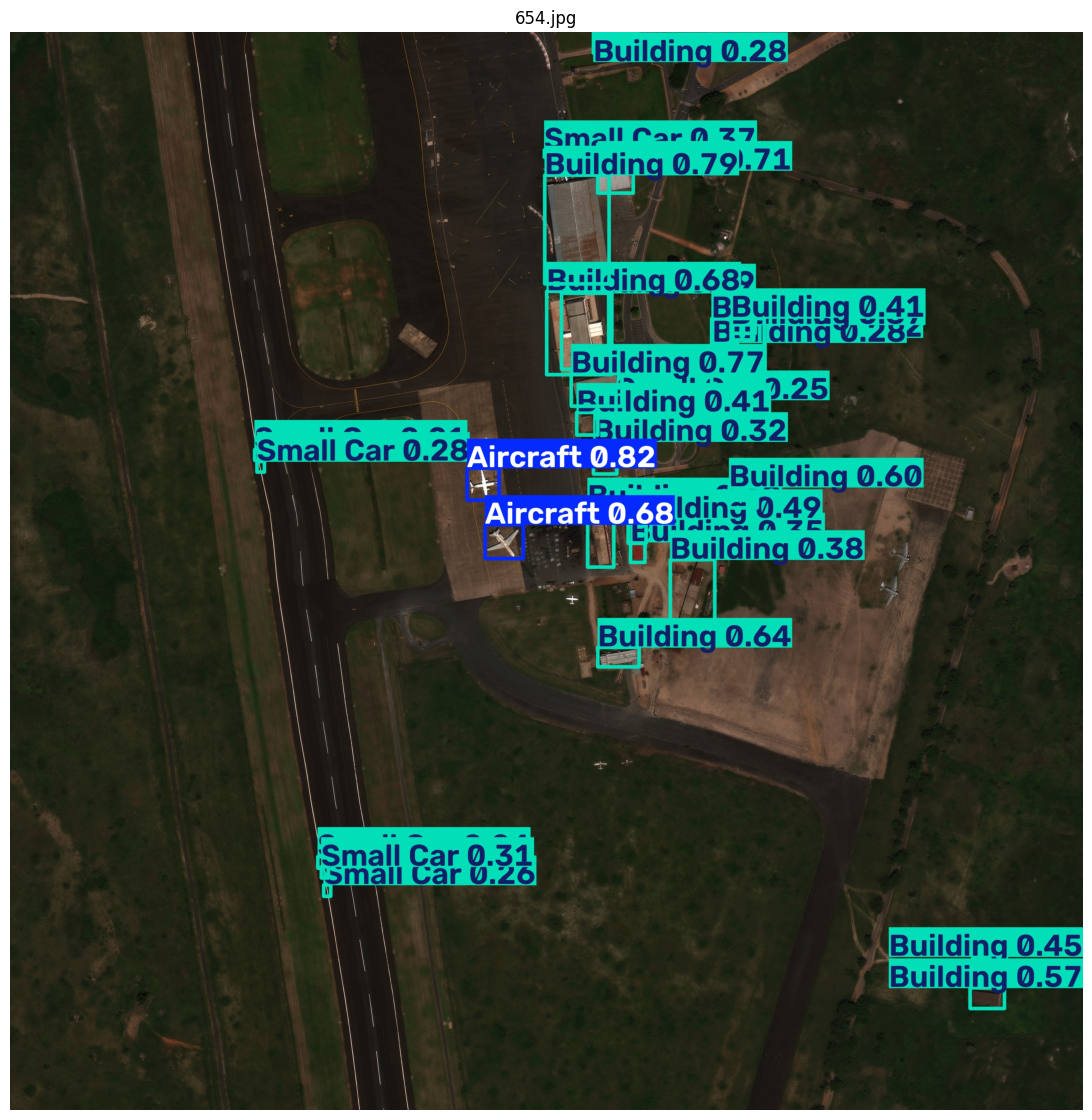

In [16]:
import matplotlib.pyplot as plt
from PIL import Image

demo_dir = "/content/xView_local/runs/inference_demo2"
demo_files = [f for f in os.listdir(demo_dir) if f.endswith(('.jpg', '.png'))]

if demo_files:
    img = Image.open(os.path.join(demo_dir, demo_files[0]))
    plt.figure(figsize=(14, 14))
    plt.imshow(img)
    plt.axis('off')
    plt.title(demo_files[0])
    plt.show()

In [18]:
drive_demo = "/content/drive/MyDrive/Fun_projects/Detection_objets_sur_imagerie_satellite/data_lake/xView/inference_demo2"
if not os.path.exists(drive_demo):
    shutil.copytree(demo_dir, drive_demo)
    print("Résultats de démo sauvegardés sur Drive.")

Résultats de démo sauvegardés sur Drive.


In [ ]:
results = model.predict("/content/xView_local/val_images/636.tif", save=True, conf=0.10, project="/content/xView_local/runs", name="debug_low_conf")


image 1/1 /content/xView_local/val_images/636.tif: 608x640 1 Building, 5 Pylons, 187.1ms
Speed: 6.4ms preprocess, 187.1ms inference, 1.1ms postprocess per image at shape (1, 3, 608, 640)
Results saved to /content/xView_local/runs/debug_low_conf


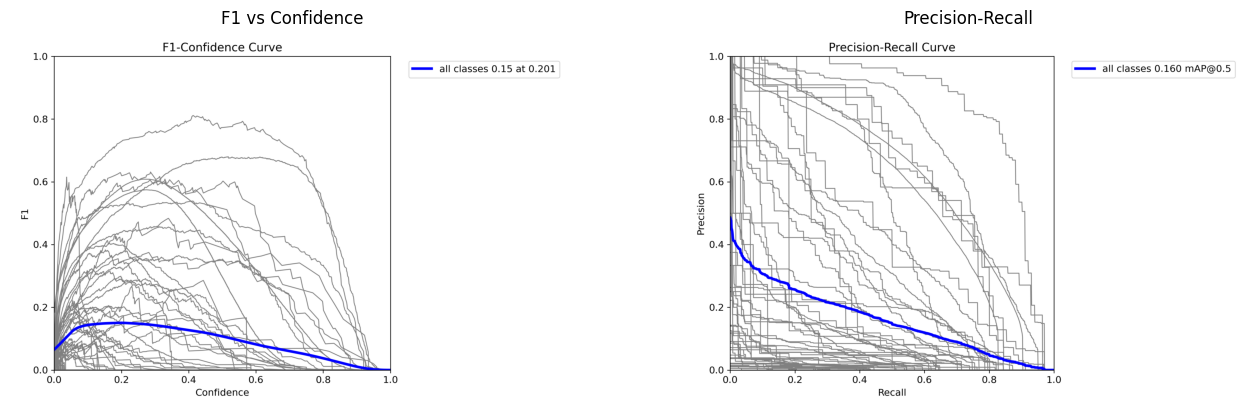

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

f1_curve = Image.open("/content/xView_local/runs/xview_yolov8n/BoxF1_curve.png")
pr_curve = Image.open("/content/xView_local/runs/xview_yolov8n/BoxPR_curve.png")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].imshow(f1_curve)
axes[0].axis('off')
axes[0].set_title("F1 vs Confidence")
axes[1].imshow(pr_curve)
axes[1].axis('off')
axes[1].set_title("Precision-Recall")
plt.show()

In [20]:
from ultralytics import YOLO

best_weights_path = f"{drive_runs}/weights/best.pt"
model_final = YOLO(best_weights_path)

CONF_THRESHOLD = 0.24

def detect(image_path, conf=CONF_THRESHOLD):
    results = model_final.predict(image_path, conf=conf, verbose=False)[0]
    detections = []
    for box in results.boxes:
        cls_id = int(box.cls[0])
        detections.append({
            "class": model_final.names[cls_id],
            "confidence": float(box.conf[0]),
            "bbox_xyxy": box.xyxy[0].tolist()
        })
    return detections

In [22]:
import os

sample_image = "/content/xView_local/val_images"
result = detect(sample_image)

print(f"Image testée : {sample_image}")
print(f"{len(result)} objets détectés\n")
for d in result[:10]:
    print(f"{d['class']:25s} conf={d['confidence']:.2f}")

KeyboardInterrupt: 